In [1]:
# CELDA 1 — Instalar dependencias (ejecutar si no lo hiciste)
!pip install -q tensorflow opencv-python-headless scikit-learn matplotlib seaborn

In [2]:
# @title CELDA 3: Verificación de Estructura y Conteo de Imágenes Final
import os

# --- 1. CONFIGURACIÓN ---
# Definimos la carpeta aquí mismo para asegurar que funcione
DATA_DIR = 'dataset_desbalanceado'

# Lista de cosas que NO son clases (basura del sistema)
NON_CLASS_ARTIFACTS = ['__MACOSX', '.ipynb_checkpoints', '.DS_Store']

# --- 2. FUNCIONES ---
def count_images(folder):
    """Cuenta archivos de imagen (jpg, png, etc.) en la carpeta dada."""
    cnt = 0
    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
    
    if os.path.isdir(folder):
        for f in os.listdir(folder):
            if f.lower().endswith(valid_exts):
                cnt += 1
    return cnt

# --- 3. EJECUCIÓN PRINCIPAL ---
print(f"🔍 Verificando carpeta: '{DATA_DIR}'...\n")

if not os.path.exists(DATA_DIR):
    print(f"❌ ERROR: No se encontró la carpeta '{DATA_DIR}'.")
    print("   👉 Asegúrate de haber ejecutado la descompresión (Celda 2) correctamente.")
else:
    try:
        # Listar todo el contenido de la carpeta principal
        all_items = os.listdir(DATA_DIR)

        # FILTRO INTELIGENTE:
        # 1. Debe ser una carpeta (isdir)
        # 2. No debe estar en la lista de prohibidos (NON_CLASS_ARTIFACTS)
        # 3. No debe empezar con punto (archivos ocultos de Linux/Colab)
        classes = sorted([d for d in all_items
                          if os.path.isdir(os.path.join(DATA_DIR, d))
                          and d not in NON_CLASS_ARTIFACTS
                          and not d.startswith('.')])

        num_classes = len(classes)

        if num_classes == 0:
            print("⚠️ ALERTA: La carpeta existe, pero NO se detectaron subcarpetas de clases.")
            print(f"   Contenido encontrado: {all_items}")
        else:
            print(f"✅ Clases detectadas ({num_classes}): {classes}")
            print("-" * 40)
            print(f"{'CLASE':<20} | {'IMÁGENES':<10}")
            print("-" * 40)

            total_images = 0

            # Contar imágenes por cada clase
            for c in classes:
                path_to_class = os.path.join(DATA_DIR, c)
                num_images = count_images(path_to_class)
                
                print(f"{c:<20} | {num_images:<10}")
                total_images += num_images

            print("-" * 40)
            print(f"📊 TOTAL GENERAL:      {total_images}")
            print("-" * 40)

    except Exception as e:
        print(f"\n❌ Ocurrió un error inesperado al leer los archivos: {e}")

🔍 Verificando carpeta: 'dataset_desbalanceado'...

✅ Clases detectadas (3): ['roya_comun', 'sana', 'tizon_foliar']
----------------------------------------
CLASE                | IMÁGENES  
----------------------------------------
roya_comun           | 97        
sana                 | 701       
tizon_foliar         | 294       
----------------------------------------
📊 TOTAL GENERAL:      1092
----------------------------------------


In [4]:
import os
import cv2
import random
import albumentations as A
from tqdm import tqdm

# ==================================================
# CONFIGURACIÓN GENERAL
# ==================================================
DATASET_DIR = "dataset_desbalanceado"
TARGET_COUNT = 650
IMG_EXTS = (".jpg", ".jpeg", ".png")

CLASSES_TO_AUGMENT = ["roya_comun", "tizon_foliar"]

# ==================================================
# PIPELINE DE AUMENTO DEFINITIVO (SIN CONFUSIÓN)
# ==================================================
augmenter = A.Compose([

    # --- ROTACIÓN ±5° CON FONDO NEGRO ---
    A.Rotate(
        limit=5,
        border_mode=cv2.BORDER_CONSTANT,
        value=(0, 0, 0),
        p=0.5
    ),

    # --- FLIP HORIZONTAL (SEGURO) ---
    A.HorizontalFlip(p=0.3),

    # --- ZOOM LEVE (API CORRECTA) ---
    A.RandomResizedCrop(
        size=(224, 224),
        scale=(0.92, 1.0),
        ratio=(0.97, 1.03),
        p=0.4
    ),

    # --- ILUMINACIÓN SUAVE ---
    A.RandomBrightnessContrast(
        brightness_limit=0.07,
        contrast_limit=0.07,
        p=0.3
    ),

    # --- CONTRASTE LOCAL ---
    A.CLAHE(
        clip_limit=2.0,
        tile_grid_size=(8, 8),
        p=0.3
    ),
])


# ==================================================
# FUNCIÓN DE AUMENTO POR CLASE
# ==================================================
def augment_class(class_path):
    images = [f for f in os.listdir(class_path) if f.lower().endswith(IMG_EXTS)]
    current = len(images)

    if current >= TARGET_COUNT:
        print(f"✅ {os.path.basename(class_path)} ya tiene {current} imágenes")
        return

    needed = TARGET_COUNT - current
    print(f"⚙️ Aumentando {os.path.basename(class_path)}: {current} → {TARGET_COUNT}")

    for i in tqdm(range(needed)):
        img_name = random.choice(images)
        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        aug_img = augmenter(image=img)["image"]

        out_name = f"aug_{current+i:04d}.jpg"
        out_path = os.path.join(class_path, out_name)

        cv2.imwrite(out_path, cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

# ==================================================
# EJECUCIÓN CONTROLADA
# ==================================================
print(f"\n🔍 Dataset: {DATASET_DIR}\n")

for cls in CLASSES_TO_AUGMENT:
    cls_dir = os.path.join(DATASET_DIR, cls)
    if not os.path.isdir(cls_dir):
        print(f"❌ No existe la carpeta: {cls}")
        continue
    augment_class(cls_dir)

print("\n✅ AUMENTO COMPLETADO (PIPELINE CORREGIDO Y PROPORCIONAL)")


C:\Users\User\AppData\Local\Temp\ipykernel_15568\4026786650.py:22: UserWarning: Argument(s) 'value' are not valid for transform Rotate
  A.Rotate(



🔍 Dataset: dataset_desbalanceado

⚙️ Aumentando roya_comun: 97 → 650


100%|██████████| 553/553 [01:19<00:00,  6.92it/s]


⚙️ Aumentando tizon_foliar: 294 → 650


100%|██████████| 356/356 [00:41<00:00,  8.55it/s]


✅ AUMENTO COMPLETADO (PIPELINE CORREGIDO Y PROPORCIONAL)


In [5]:
# @title CELDA 5: División 70/15/15 y Creación de tf.data (Dataset Balanceado)
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# --- 1. CONFIGURACIÓN ---
# Usamos explícitamente la carpeta que acabamos de crear en la Celda 4
DATASET_PATH = 'dataset_desbalanceado'
IMG_SIZE = 224 # Tamaño estándar para EfficientNet/ResNet
BATCH_SIZE = 32

print(f"📂 Cargando imágenes desde: {DATASET_PATH}")

# --- 2. CARGAR RUTAS Y ETIQUETAS ---
try:
    # Obtener nombres de clases ordenados alfabéticamente
    class_names = sorted([d for d in os.listdir(DATASET_PATH) 
                          if os.path.isdir(os.path.join(DATASET_PATH, d))])
    num_classes = len(class_names)
    print(f"✅ Clases detectadas ({num_classes}): {class_names}")

    filepaths = []
    labels = []

    for idx, cls in enumerate(class_names):
        class_dir = os.path.join(DATASET_PATH, cls)
        # Buscar imágenes recursivamente
        for root, dirs, files in os.walk(class_dir):
            for f in files:
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                    filepaths.append(os.path.join(root, f))
                    labels.append(idx)
    
    print(f"📊 Total de imágenes encontradas: {len(filepaths)}")

except FileNotFoundError:
    print(f"❌ ERROR: No existe la carpeta '{DATASET_PATH}'. Ejecuta la Celda 4 primero.")
    raise

# --- 3. DIVISIÓN ESTRATIFICADA (70% Train - 15% Val - 15% Test) ---
# Convertir a numpy para facilitar manejo
filepaths = np.array(filepaths)
labels = np.array(labels)

# PASO A: Separar el 15% para TEST (El resto es 85%)
X_temp, X_test, y_temp, y_test = train_test_split(
    filepaths, labels, 
    test_size=0.15, 
    stratify=labels, 
    random_state=42
)

# PASO B: Separar el 15% (del total original) para VALIDACIÓN
# Como nos queda el 85% de los datos, calculamos: 15 / 85 = 0.1765
val_split = 0.15 / 0.85 
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, 
    test_size=val_split, 
    stratify=y_temp, 
    random_state=42
)

print("-" * 50)
print(f"TRAIN (Entrenamiento 70%): {len(X_train)} imágenes")
print(f"VAL   (Validación 15%):    {len(X_val)} imágenes")
print(f"TEST  (Prueba 15%):        {len(X_test)} imágenes")
print("-" * 50)

# --- 4. CONSTRUCCIÓN DE TF.DATA (Optimización) ---

def process_path(file_path, label):
    """Carga, decodifica y redimensiona la imagen"""
    # Cargar archivo
    img = tf.io.read_file(file_path)
    # Decodificar (detecta jpg o png automáticamente)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    # Convertir a float32 y normalizar [0,1]
    img = tf.cast(img, tf.float32) / 255.0
    # Redimensionar (EfficientNet necesita tamaño fijo)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img, label

def configure_for_performance(ds, is_train=False):
    """Optimiza el pipeline de carga"""
    # Cachear en memoria si cabe, sino en disco
    # ds = ds.cache() 
    if is_train:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

# Crear los Datasets de TensorFlow
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Mapear la función de procesamiento
train_ds = train_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)

# Optimizar rendimiento
train_dataset = configure_for_performance(train_ds, is_train=True)
val_dataset = configure_for_performance(val_ds)
test_dataset = configure_for_performance(test_ds)

print("✅ Pipelines de tf.data creados exitosamente.")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Image Size: {IMG_SIZE}x{IMG_SIZE}")

📂 Cargando imágenes desde: dataset_desbalanceado
✅ Clases detectadas (3): ['roya_comun', 'sana', 'tizon_foliar']
📊 Total de imágenes encontradas: 2001
--------------------------------------------------
TRAIN (Entrenamiento 70%): 1400 imágenes
VAL   (Validación 15%):    300 imágenes
TEST  (Prueba 15%):        301 imágenes
--------------------------------------------------
✅ Pipelines de tf.data creados exitosamente.
   Batch size: 32
   Image Size: 224x224


⚠️ AVISO: Entrenando con CPU (Puede ser lento).


Model: "EfficientNetB0_Maiz_Local"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

...

44/44 ━━━━━━━━━━━━━━━━━━━━ 47s 644ms/step - accuracy: 0.9307 - loss: 0.2008 - val_accuracy: 0.8967 - val_loss: 0.2589
Epoch 32/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.9270 - loss: 0.1831
Epoch 32: val_accuracy did not improve from 0.89667
44/44 ━━━━━━━━━━━━━━━━━━━━ 56s 872ms/step - accuracy: 0.9257 - loss: 0.1999 - val_accuracy: 0.8967 - val_loss: 0.2584
Epoch 33/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.9278 - loss: 0.2059
Epoch 33: val_accuracy did not improve from 0.89667
44/44 ━━━━━━━━━━━━━━━━━━━━ 49s 640ms/step - accuracy: 0.9329 - loss: 0.1954 - val_accuracy: 0.8867 - val_loss: 0.2699
Epoch 34/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.9383 - loss: 0.1724
Epoch 34: val_accuracy improved from 0.89667 to 0.90000, saving model to mejor_modelo_maiz.keras.h5


44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 640ms/step - accuracy: 0.9250 - loss: 0.1986 - val_accuracy: 0.9000 - val_loss: 0.2606
Epoch 35/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.9386 - loss: 0.1788
Epoch 35: val_accuracy did not improve from 0.90000
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 637ms/step - accuracy: 0.9321 - loss: 0.1896 - val_accuracy: 0.8967 - val_loss: 0.2630
Epoch 36/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.9302 - loss: 0.1979
Epoch 36: val_accuracy did not improve from 0.90000
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 632ms/step - accuracy: 0.9314 - loss: 0.1929 - val_accuracy: 0.9000 - val_loss: 0.2535
Epoch 37/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.9183 - loss: 0.2053
Epoch 37: val_accuracy did not improve from 0.90000
44/44 ━━━━━━━━━━━━━━━━━━━━ 50s 643ms/step - accuracy: 0.9350 - loss: 0.1890 - val_accuracy: 0.8967 - val_loss: 0.2570
Epoch 38/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9372 - loss: 0.1763
Epoch 38: val_accura

44/44 ━━━━━━━━━━━━━━━━━━━━ 48s 659ms/step - accuracy: 0.9364 - loss: 0.1771 - val_accuracy: 0.9033 - val_loss: 0.2557
Epoch 39/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.9394 - loss: 0.1807
Epoch 39: val_accuracy did not improve from 0.90333
44/44 ━━━━━━━━━━━━━━━━━━━━ 48s 659ms/step - accuracy: 0.9379 - loss: 0.1869 - val_accuracy: 0.9033 - val_loss: 0.2535
Epoch 40/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.9355 - loss: 0.1746
Epoch 40: val_accuracy did not improve from 0.90333
44/44 ━━━━━━━━━━━━━━━━━━━━ 47s 657ms/step - accuracy: 0.9336 - loss: 0.1834 - val_accuracy: 0.9033 - val_loss: 0.2511
Epoch 41/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.9376 - loss: 0.1622
Epoch 41: val_accuracy did not improve from 0.90333
44/44 ━━━━━━━━━━━━━━━━━━━━ 53s 720ms/step - accuracy: 0.9307 - loss: 0.1777 - val_accuracy: 0.9000 - val_loss: 0.2461
Epoch 42/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 569ms/step - accuracy: 0.9393 - loss: 0.1746
Epoch 42: val_accura

44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 633ms/step - accuracy: 0.9300 - loss: 0.1852 - val_accuracy: 0.9100 - val_loss: 0.2465
Epoch 45/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.9268 - loss: 0.1788
Epoch 45: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 618ms/step - accuracy: 0.9336 - loss: 0.1773 - val_accuracy: 0.9100 - val_loss: 0.2416
Epoch 46/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.9340 - loss: 0.1762
Epoch 46: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 627ms/step - accuracy: 0.9329 - loss: 0.1785 - val_accuracy: 0.9000 - val_loss: 0.2576
Epoch 47/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.9240 - loss: 0.1790
Epoch 47: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 623ms/step - accuracy: 0.9321 - loss: 0.1807 - val_accuracy: 0.9033 - val_loss: 0.2448
Epoch 48/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 482ms/step - accuracy: 0.9401 - loss: 0.1683
Epoch 48: val_accura

44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 636ms/step - accuracy: 0.9379 - loss: 0.1691 - val_accuracy: 0.9133 - val_loss: 0.2524
Epoch 50/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.9503 - loss: 0.1652
Epoch 50: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 627ms/step - accuracy: 0.9429 - loss: 0.1716 - val_accuracy: 0.9067 - val_loss: 0.2344
Epoch 51/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.9321 - loss: 0.1844
Epoch 51: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 642ms/step - accuracy: 0.9336 - loss: 0.1769 - val_accuracy: 0.9133 - val_loss: 0.2371
Epoch 52/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.9432 - loss: 0.1595
Epoch 52: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 631ms/step - accuracy: 0.9393 - loss: 0.1704 - val_accuracy: 0.9100 - val_loss: 0.2391
Epoch 53/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.9438 - loss: 0.1626
Epoch 53: val_accura

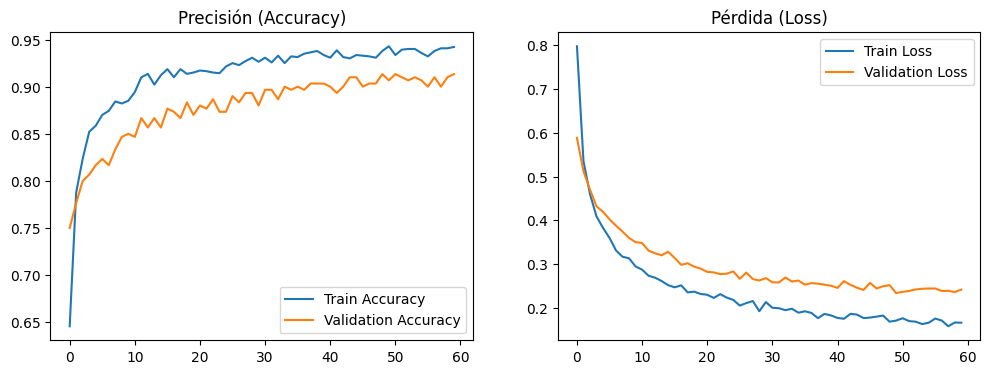


✅ PROCESO COMPLETADO.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, applications, callbacks
import matplotlib.pyplot as plt

# ==================================================
# 1. CONFIGURACIÓN GPU (LOCAL)
# ==================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"✅ GPU Configurada: {len(gpus)} dispositivo(s).")
else:
    print("⚠️ Entrenando con CPU.")

# ==================================================
# 2. CONFIGURACIÓN DE CLASES (FIJADAS)
# ==================================================
class_names = ["roya_comun", "sana", "tizon_foliar"]
num_classes = len(class_names)

# ==================================================
# 3. MODELO BASE: EfficientNetB0
# ==================================================
base_model = applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# ==================================================
# 4. ARQUITECTURA COMPLETA
# ==================================================
inputs = layers.Input(shape=(224, 224, 3))

# Restaurar rango [0,255] porque tf.data ya normaliza
x = layers.Rescaling(255.0)(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs, name="EfficientNetB0_Maiz")

# ✅ incrustar clases EN EL MODELO
model.class_names = class_names

# ==================================================
# 5. COMPILACIÓN
# ==================================================
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==================================================
# 6. CALLBACKS CORRECTOS
# ==================================================
checkpoint_path = "mejor_modelo_maiz.keras"

callbacks_list = [
    callbacks.ModelCheckpoint(
        checkpoint_path,
        save_best_only=True,
        monitor="val_accuracy",
        mode="max",
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]

# ==================================================
# 7. ENTRENAMIENTO
# ==================================================
print("\n🚀 INICIANDO ENTRENAMIENTO (EfficientNetB0)...")

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    callbacks=callbacks_list
)

# ==================================================
# 8. VISUALIZACIÓN
# ==================================================
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Train Accuracy")
plt.plot(val_acc, label="Val Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train Loss")
plt.plot(val_loss, label="Val Loss")
plt.legend()
plt.title("Loss")

plt.show()

print("\n✅ ENTRENAMIENTO COMPLETADO.")


🔍 Generando predicciones sobre el conjunto de prueba...
✅ Predicciones completadas.
------------------------------------------------------------

📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):

              precision    recall  f1-score   support

  roya_comun     0.9700    0.9898    0.9798        98
        sana     0.8750    0.8667    0.8708       105
tizon_foliar     0.8454    0.8367    0.8410        98

    accuracy                         0.8970       301
   macro avg     0.8968    0.8977    0.8972       301
weighted avg     0.8963    0.8970    0.8966       301



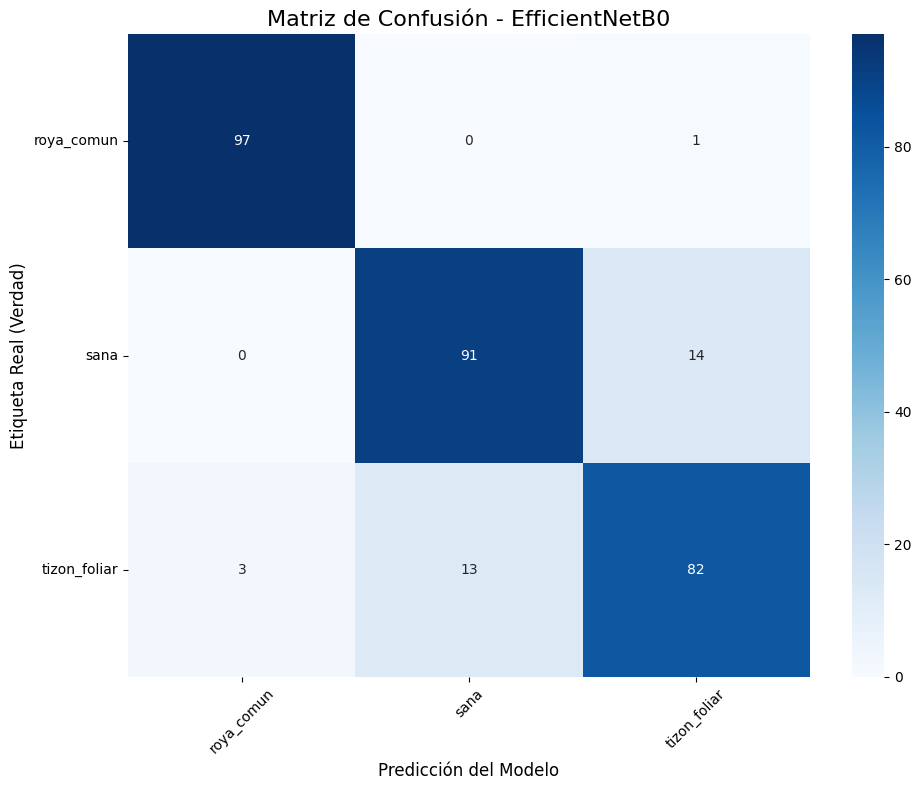

------------------------------------------------------------
🏆 EXACTITUD GLOBAL (Accuracy): 89.70%
------------------------------------------------------------


In [7]:
# @title CELDA 7: Evaluación de Métricas y Matriz de Confusión
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. OBTENER PREDICCIONES Y ETIQUETAS REALES ---
print("🔍 Generando predicciones sobre el conjunto de prueba...")

# Extraemos las etiquetas verdaderas (y_true) y las predicciones (y_pred)
y_true = []
y_pred_probs = []

# Iteramos sobre el dataset de prueba (batch por batch para no saturar memoria)
for images, labels in test_dataset:
    # Predicción del modelo (probabilidades)
    probs = model.predict(images, verbose=0)
    
    # Guardamos resultados
    y_true.extend(labels.numpy())
    y_pred_probs.extend(probs)

# Convertimos a arrays de numpy
y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
# Convertimos probabilidades a etiquetas (0, 1, 2, 3) tomando el valor más alto
y_pred = np.argmax(y_pred_probs, axis=1)

print("✅ Predicciones completadas.")
print("-" * 60)

# --- 2. REPORTE DE CLASIFICACIÓN (TABLA DE MÉTRICAS) ---
print("\n📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):\n")

report = classification_report(
    y_true, 
    y_pred, 
    target_names=class_names, # Usa los nombres de tus carpetas
    digits=4 # 4 decimales para mayor precisión
)
print(report)

# --- 3. MATRIZ DE CONFUSIÓN (GRÁFICO) ---
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True,         # Mostrar números dentro de los cuadros
    fmt='d',            # Formato entero (sin decimales)
    cmap='Blues',       # Color azul profesional
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Matriz de Confusión - EfficientNetB0', fontsize=16)
plt.ylabel('Etiqueta Real (Verdad)', fontsize=12)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --- 4. EXPLICACIÓN RÁPIDA ---
acc = np.sum(y_pred == y_true) / len(y_true)
print("-" * 60)
print(f"🏆 EXACTITUD GLOBAL (Accuracy): {acc:.2%}")
print("-" * 60)

📂 Abriendo explorador de archivos...
✅ Archivo seleccionado: IMG_20251005_121240.jpg
🧠 Analizando imagen...


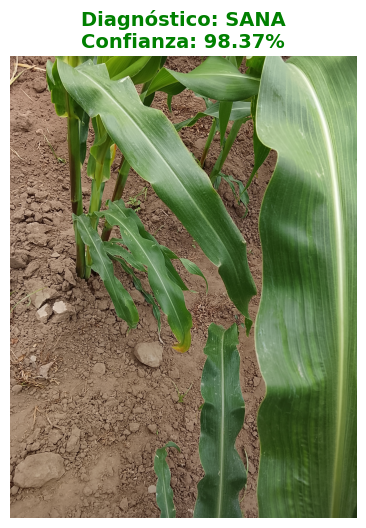

--------------------------------------------------
🌽 RESULTADO DEL DIAGNÓSTICO:
   ➤ Enfermedad Detectada: SANA
   ➤ Nivel de Confianza:   98.37%
   ➤ Tiempo de Análisis:   0.1623 seg
--------------------------------------------------
📊 Probabilidades por clase:
   - roya_comun          : 0.01% 
   - sana                : 98.37% ◄ GANADORA
   - tizon_foliar        : 1.62% 


In [27]:
# @title CELDA 13: Prueba con Imagen Real (Ventana Windows Directa)
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import tkinter as tk
from tkinter import filedialog

# --- 1. ABRIR VENTANA DE WINDOWS DIRECTAMENTE ---
print("📂 Abriendo explorador de archivos...")

# Crear la instancia de Tkinter
root = tk.Tk()

# TRUCOS PARA FORZAR LA VENTANA AL FRENTE (ENCIMA DE VS CODE/CHROME)
root.attributes('-topmost', True)  # Mantener siempre encima
root.lift()                        # Levantar la ventana
root.focus_force()                 # Robar el foco del teclado/mouse
root.withdraw()                    # Ocultar la caja gris fea, dejar solo el diálogo

# Abrir el explorador de archivos
file_path = filedialog.askopenfilename(
    parent=root,
    title="SELECCIONA UNA IMAGEN DE MAÍZ",
    filetypes=[("Imágenes", "*.jpg *.jpeg *.png *.bmp *.webp")]
)

# Destruir la instancia inmediatamente después de elegir
root.destroy()

# --- 2. VERIFICAR SELECCIÓN ---
if not file_path:
    print("❌ Cancelaste la selección o cerraste la ventana.")
else:
    print(f"✅ Archivo seleccionado: {os.path.basename(file_path)}")

    # --- 3. PREPROCESAMIENTO ---
    # Cargar y redimensionar a 224x224
    img_size = (224, 224) 
    
    # Cargar imagen para visualización (original)
    img_display = image.load_img(file_path)
    
    # Cargar imagen para el modelo (tensor)
    img_tensor = image.load_img(file_path, target_size=img_size)
    img_array = image.img_to_array(img_tensor)
    img_array = img_array / 255.0  # Normalizar [0, 1]
    
    # Crear lote de 1 imagen
    img_batch = np.expand_dims(img_array, axis=0)

    # --- 4. PREDICCIÓN ---
    print("🧠 Analizando imagen...")
    start = time.time()
    predictions = model.predict(img_batch, verbose=0)
    end = time.time()
    
    # --- 5. RESULTADOS ---
    predicted_idx = np.argmax(predictions[0])
    predicted_label = class_names[predicted_idx]
    confidence = np.max(predictions[0]) * 100
    total_time = end - start

    # --- 6. MOSTRAR REPORTE ---
    plt.figure(figsize=(6, 6))
    plt.imshow(img_display)
    plt.axis('off')
    
    # Colorear título según seguridad del modelo
    if confidence > 90:
        color = 'green'  # Muy seguro
    elif confidence > 70:
        color = 'orange' # Duda razonable
    else:
        color = 'red'    # Inseguro (Cuidado)

    plt.title(f"Diagnóstico: {predicted_label.replace('_', ' ').upper()}\nConfianza: {confidence:.2f}%", 
              color=color, fontsize=14, fontweight='bold')
    plt.show()

    print("-" * 50)
    print(f"🌽 RESULTADO DEL DIAGNÓSTICO:")
    print(f"   ➤ Enfermedad Detectada: {predicted_label.upper()}")
    print(f"   ➤ Nivel de Confianza:   {confidence:.2f}%")
    print(f"   ➤ Tiempo de Análisis:   {total_time:.4f} seg")
    print("-" * 50)
    
    print("📊 Probabilidades por clase:")
    for i, prob in enumerate(predictions[0]):
        # Resaltar la ganadora con una flecha
        marker = "◄ GANADORA" if i == predicted_idx else ""
        print(f"   - {class_names[i]:<20}: {prob*100:.2f}% {marker}")

In [39]:
from tensorflow.keras.models import load_model

model = load_model("efficientnetB0.h5", compile=False)


In [40]:
model.metadata = {
    "class_names": ["roya_comun", "sana", "tizon_foliar"]
}


In [41]:
model.save("efficientnetB0.keras")
